In [2]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_loader import load_all, FIGURES_DIR

sns.set_theme(style="whitegrid")
datasets = load_all()
print(datasets.keys())

dict_keys(['heart', 'breast', 'diabetes'])


In [3]:
for name, (X, y) in datasets.items():
    print(f"===== {name.upper()} =====")
    print("Shape:", X.shape)
    miss = X.isna().sum()
    print("Missing values:\n", miss[miss > 0].to_string() if miss.any() else "none")
    display(X.describe().T.round(2))
    print()

===== HEART =====
Shape: (303, 13)
Missing values:
 ca      4
thal    2


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2



===== BREAST =====
Shape: (569, 30)
Missing values:
 none


,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
texture1,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
perimeter1,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
area1,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
smoothness1,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
compactness1,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
concavity1,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
concave_points1,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
symmetry1,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30
fractal_dimension1,569.0,0.06,0.01,0.05,0.06,0.06,0.07,0.10



===== DIABETES =====
Shape: (768, 8)
Missing values:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,763.0,121.69,30.54,44.00,99.00,117.00,141.00,199.00
BloodPressure,733.0,72.41,12.38,24.00,64.00,72.00,80.00,122.00
SkinThickness,541.0,29.15,10.48,7.00,22.00,29.00,36.00,99.00
Insulin,394.0,155.55,118.78,14.00,76.25,125.00,190.00,846.00
BMI,757.0,32.46,6.92,18.20,27.50,32.30,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00


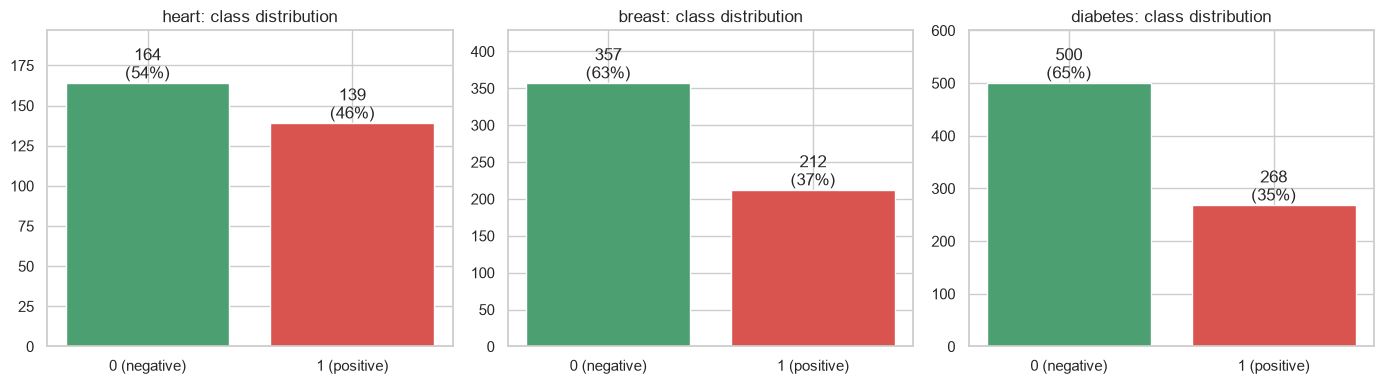

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, (X, y)) in zip(axes, datasets.items()):
    counts = y.value_counts().sort_index()
    ax.bar(["0 (negative)", "1 (positive)"], counts.values, color=["#4C9F70", "#D9534F"])
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v}\n({v/len(y):.0%})", ha="center", va="bottom")
    ax.set_title(f"{name}: class distribution")
    ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_balance.png", dpi=150)
plt.show()

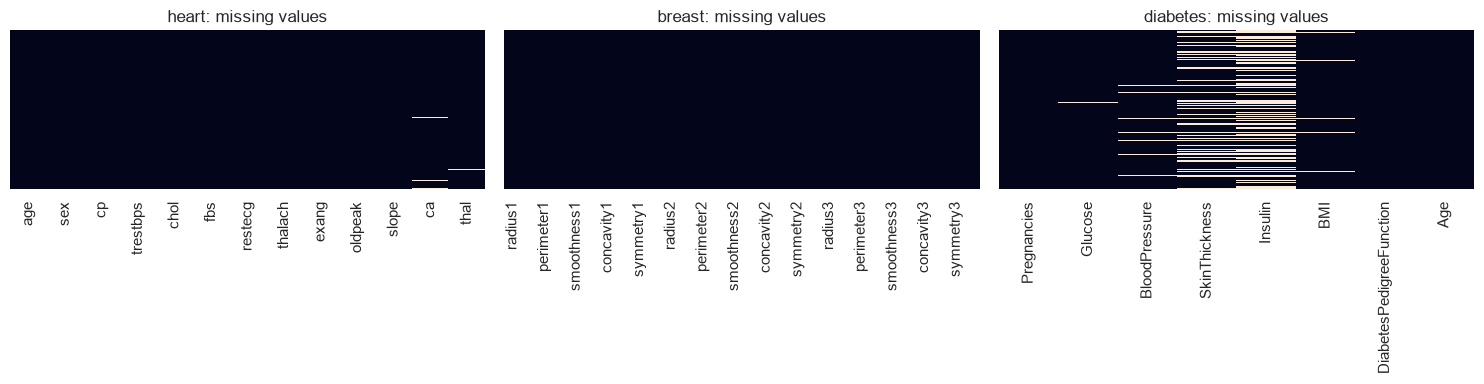

Insulin                     48.7
SkinThickness               29.6
BloodPressure                4.6
BMI                          1.4
Glucose                      0.7
Pregnancies                  0.0
DiabetesPedigreeFunction     0.0
Age                          0.0
dtype: float64


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (X, y)) in zip(axes, datasets.items()):
    sns.heatmap(X.isna(), cbar=False, yticklabels=False, ax=ax)
    ax.set_title(f"{name}: missing values")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "missing_values.png", dpi=150)
plt.show()

# Missing percentage for diabetes (zeros were converted to NaN)
Xd, _ = datasets["diabetes"]
print((Xd.isna().mean() * 100).round(1).sort_values(ascending=False))

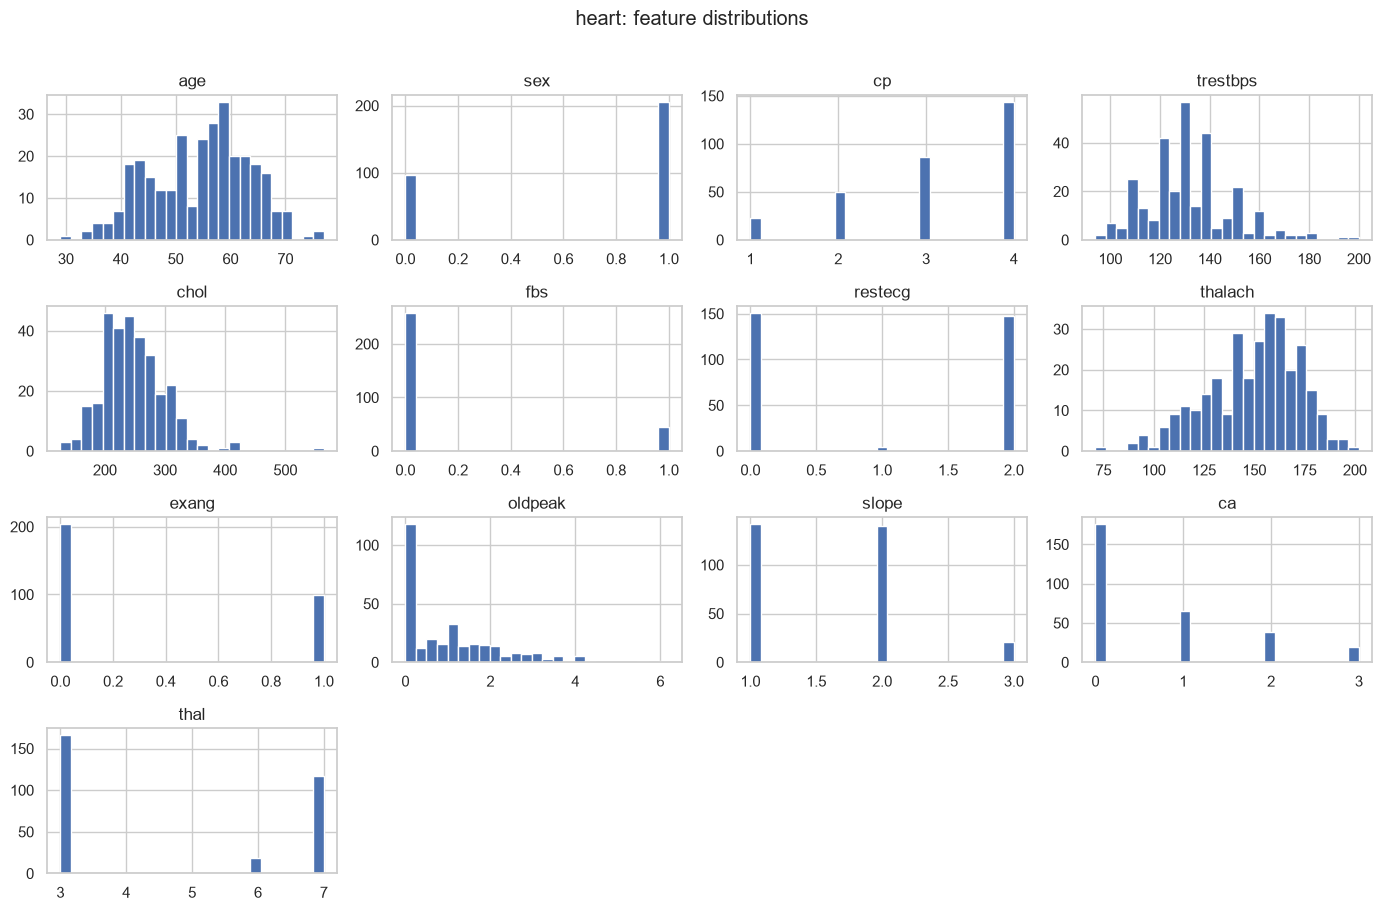

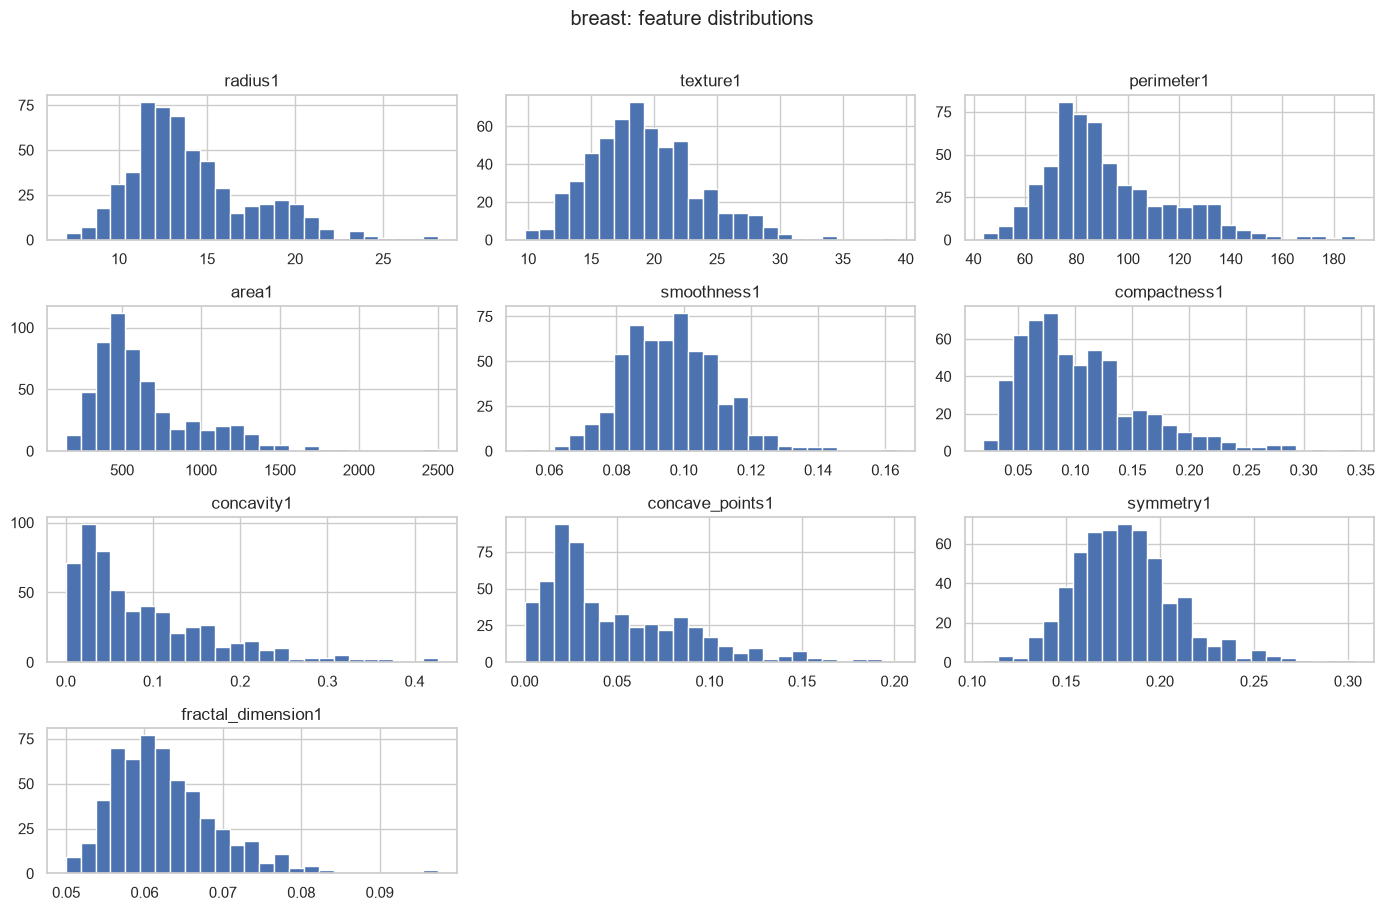

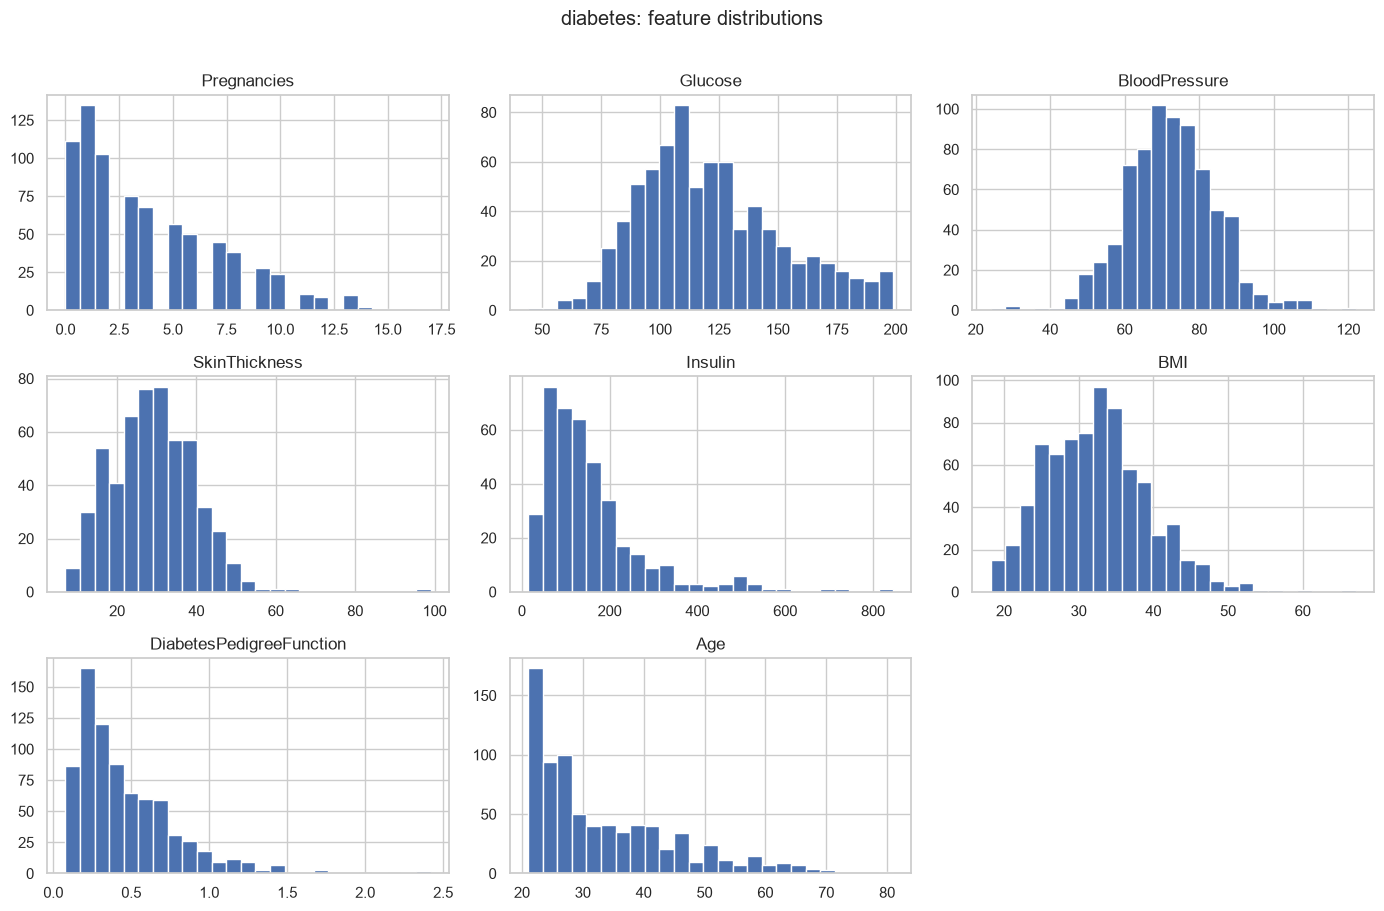

In [6]:
for name, (X, y) in datasets.items():
    cols = X.columns[:10] if name == "breast" else X.columns   # breast: first 10 (mean features)
    X[cols].hist(bins=25, figsize=(14, 9), color="#4C72B0")
    plt.suptitle(f"{name}: feature distributions", y=1.01)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}_hist.png", dpi=150)
    plt.show()

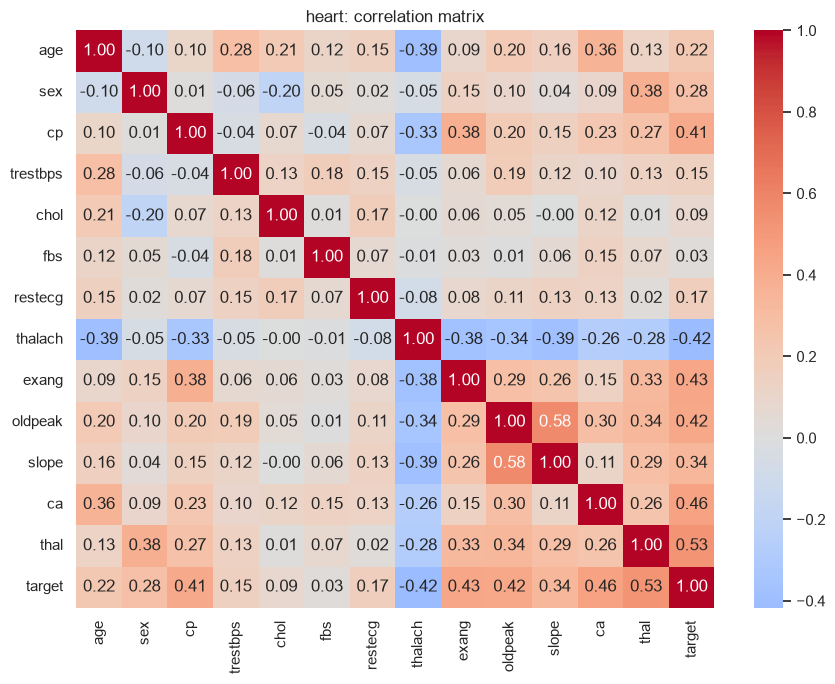


heart: top features correlated with target
thal       0.526
ca         0.460
exang      0.432
oldpeak    0.425
thalach   -0.417
cp         0.414
Name: target, dtype: float64


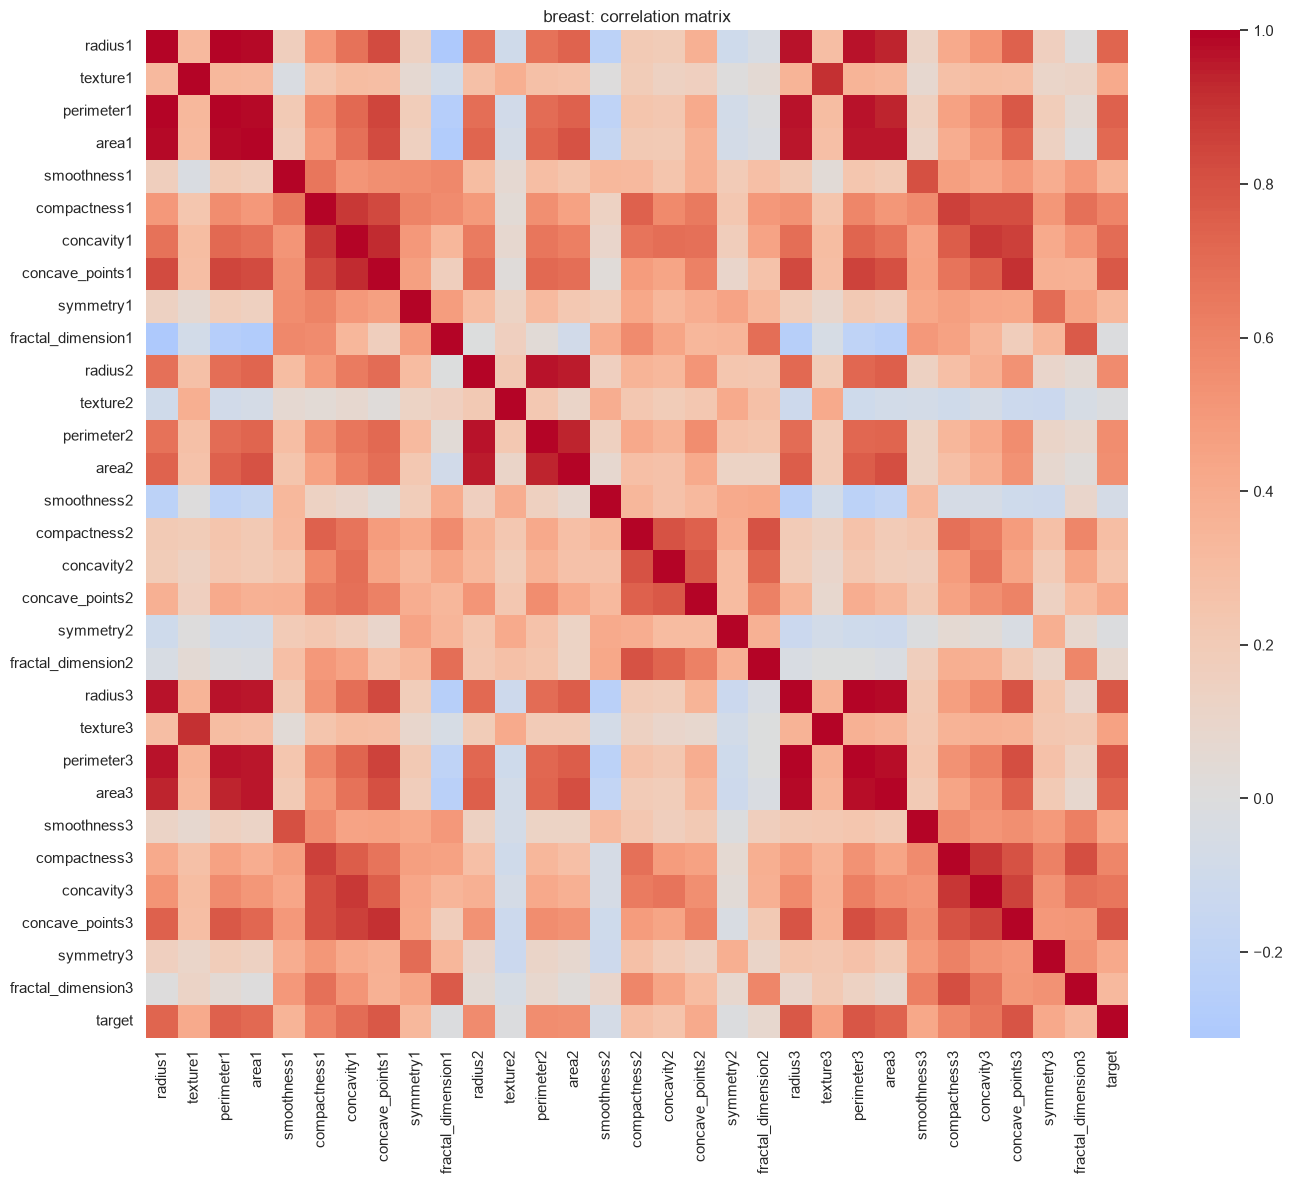


breast: top features correlated with target
concave_points3    0.794
perimeter3         0.783
concave_points1    0.777
radius3            0.776
perimeter1         0.743
area3              0.734
Name: target, dtype: float64


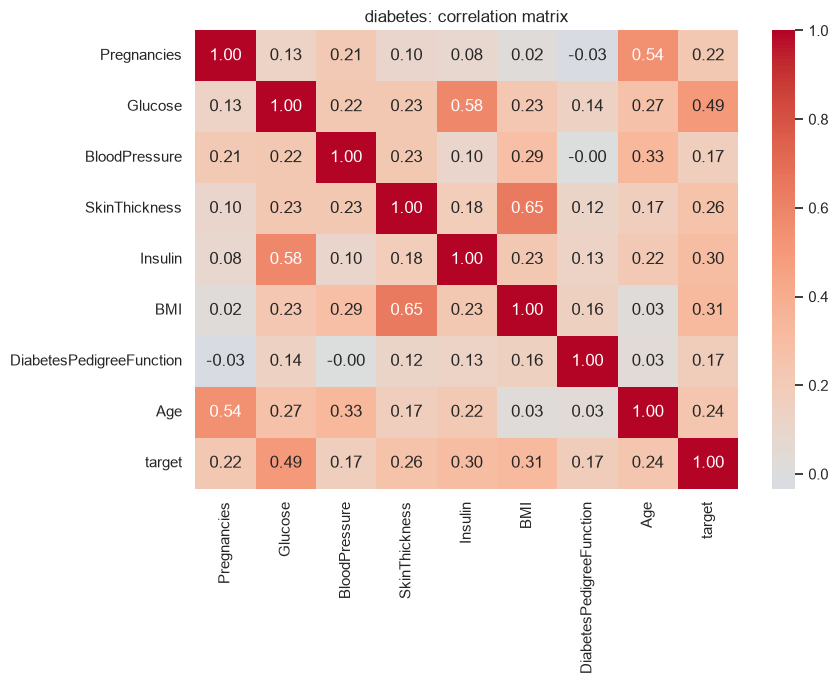


diabetes: top features correlated with target
Glucose          0.495
BMI              0.314
Insulin          0.303
SkinThickness    0.259
Age              0.238
Pregnancies      0.222
Name: target, dtype: float64


In [7]:
for name, (X, y) in datasets.items():
    df = X.copy()
    df["target"] = y
    corr = df.corr(numeric_only=True)

    size = (14, 12) if name == "breast" else (9, 7)
    plt.figure(figsize=size)
    sns.heatmap(corr, annot=(name != "breast"), fmt=".2f", cmap="coolwarm", center=0)
    plt.title(f"{name}: correlation matrix")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}_corr.png", dpi=150)
    plt.show()

    print(f"\n{name}: top features correlated with target")
    print(corr["target"].drop("target").sort_values(key=abs, ascending=False).head(6).round(3))

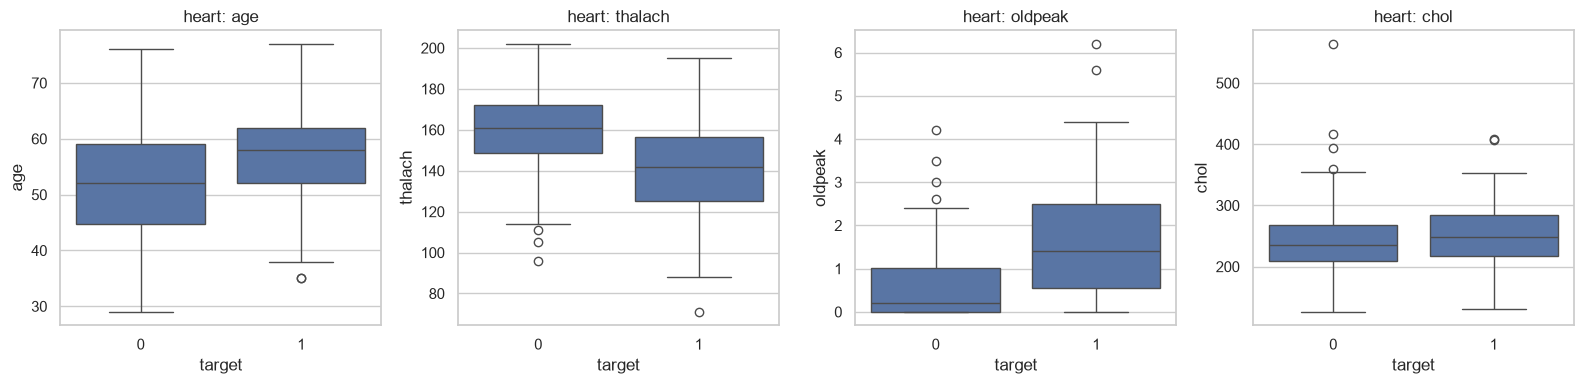

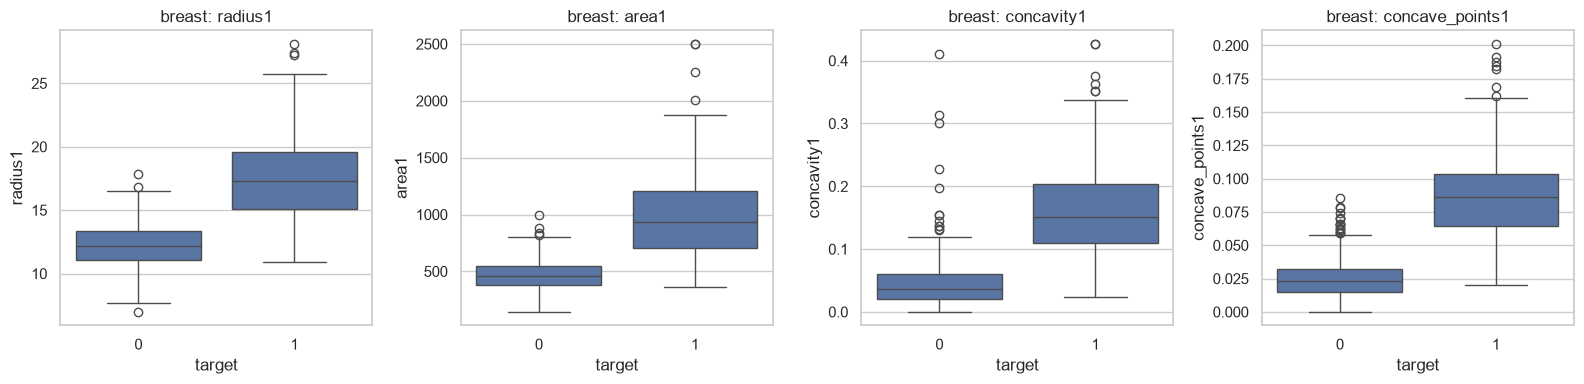

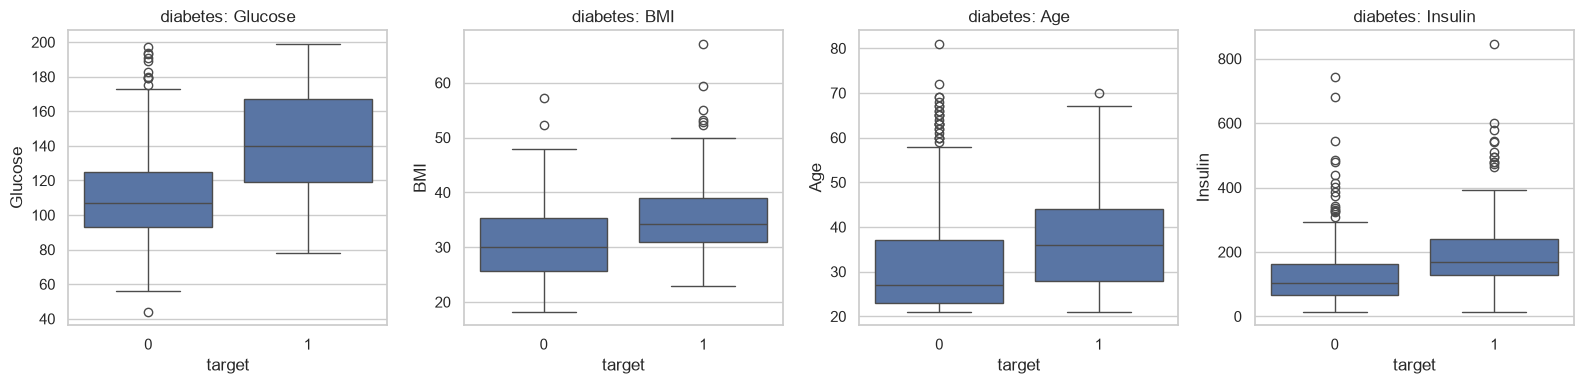

In [8]:
key_features = {
    "heart": ["age", "thalach", "oldpeak", "chol"],
    "breast": ["radius1", "area1", "concavity1", "concave_points1"],
    "diabetes": ["Glucose", "BMI", "Age", "Insulin"],
}

for name, cols in key_features.items():
    X, y = datasets[name]
    df = X.copy()
    df["target"] = y
    fig, axes = plt.subplots(1, len(cols), figsize=(16, 4))
    for ax, c in zip(axes, cols):
        sns.boxplot(data=df, x="target", y=c, ax=ax)
        ax.set_title(f"{name}: {c}")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}_boxplots.png", dpi=150)
    plt.show()

In [9]:
for name, (X, y) in datasets.items():
    num = X.select_dtypes("number")
    Q1, Q3 = num.quantile(0.25), num.quantile(0.75)
    IQR = Q3 - Q1
    out = ((num < Q1 - 1.5 * IQR) | (num > Q3 + 1.5 * IQR)).sum()
    print(f"\n{name}: columns with most outliers")
    print(out.sort_values(ascending=False).head(5).to_string())


heart: columns with most outliers
fbs         45
cp          23
ca          20
trestbps     9
chol         5

breast: columns with most outliers
area2          65
radius2        38
perimeter2     38
area3          35
smoothness2    30

diabetes: columns with most outliers
DiabetesPedigreeFunction    29
Insulin                     24
BloodPressure               14
Age                          9
BMI                          8
